In [2]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)



In [3]:
df = pd.read_csv( r"D:\python_projects\zends_project\source_data\new_data.csv")
df

,feedback_text,service_category,sentiment
0,"This week, I am satisfied overall because rout...",Broadband Service,Positive
1,"Honestly, I am somewhat satisfied because mont...",Billing & Payments,Positive
2,"Since yesterday, I feel totally upset because ...",Broadband Service,Negative
3,"Today, I am extremely happy because identity v...",Service Activation,Positive
4,"After recent update, I feel disappointed becau...",Mobile App Issues,Negative
...,...,...,...
5170,My new SIM card was activated within minutes.,Service Activation,Positive
5171,High speed fiber broadband works without any i...,Broadband Service,Positive
5172,Billing is clear and payment went through smoo...,Billing & Payments,Positive
5173,The mobile app is super smooth and easy to use.,Mobile App Issues,Positive


In [10]:
(df[df['sentiment'].str.lower() == 'neutral'])


,feedback_text,service_category,sentiment
10,"After recent update, I expected better perform...",Mobile Network,Neutral
21,"Recently, I expected better performance becaus...",Mobile App Issues,Neutral
25,"Unfortunately, I expected better performance b...",Service Activation,Neutral
43,"Unfortunately, I expected better performance b...",Service Activation,Neutral
44,"Seriously, I expected better performance becau...",Billing & Payments,Neutral
...,...,...,...
5128,"Recently, I expected better performance becaus...",Mobile App Issues,Neutral
5132,"This week, I expected better performance becau...",Billing & Payments,Neutral
5138,"Honestly, I expected better performance becaus...",Mobile Network,Neutral
5139,"This week, I expected better performance becau...",Customer Support,Neutral


#  data understanding


In [36]:
print(' shape : ',df.shape)

print('\n---- Missing values ---')
print(df.isnull().sum())

print('\n duplicate values :' , df.duplicated().sum())

print('\n----info---')
print(df.info())

print('\n----Unique values---')
for i, col in enumerate(df.columns):
    print(i, col,'-', df[col].nunique())

print('\n----Sentiment Distribution---')
print(df["sentiment"].value_counts())

print('\n----Service Distribution---')
print(df["service_category"].value_counts())


 shape :  (5175, 3)

---- Missing values ---
feedback_text       0
service_category    0
sentiment           0
dtype: int64

 duplicate values : 0

----info---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5175 entries, 0 to 5174
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   feedback_text     5175 non-null   object
 1   service_category  5175 non-null   object
 2   sentiment         5175 non-null   object
dtypes: object(3)
memory usage: 121.4+ KB
None

----Unique values---
0 feedback_text - 5175
1 service_category - 6
2 sentiment - 3

----Sentiment Distribution---
sentiment
Positive    2566
Negative    2099
Neutral      510
Name: count, dtype: int64

----Service Distribution---
service_category
Mobile Network        884
Broadband Service     871
Billing & Payments    871
Customer Support      858
Mobile App Issues     853
Service Activation    838
Name: count, dtype: int64


# EDA

In [37]:
df_raw = df.copy()

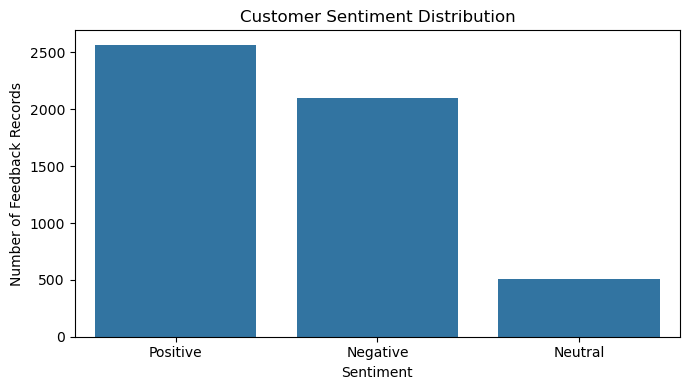

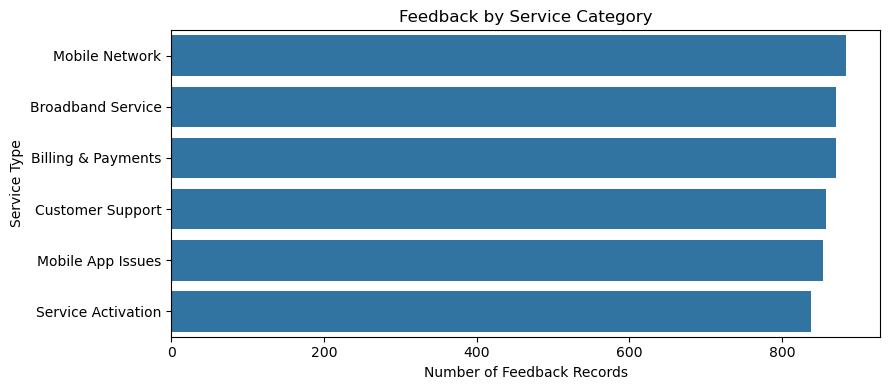

In [38]:
# 1. Sentiment distribution - original dataset
plt.figure(figsize=(7, 4))
sns.countplot(data=df_raw, x="sentiment")
plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedback Records")
plt.tight_layout()
plt.savefig("sentiment_distribution.png")
plt.show()


# 2. Service category distribution - original dataset
plt.figure(figsize=(9, 4))
sns.countplot(
    data=df_raw,
    y="service_category",
    order=df_raw["service_category"].value_counts().index
)
plt.title("Feedback by Service Category")
plt.xlabel("Number of Feedback Records")
plt.ylabel("Service Type")
plt.tight_layout()
plt.savefig("service_distribution.png")
plt.show()




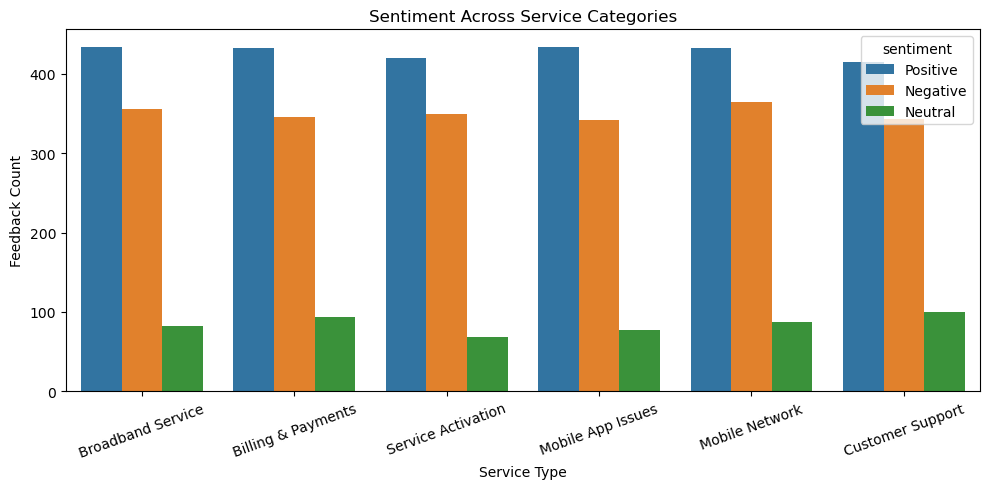

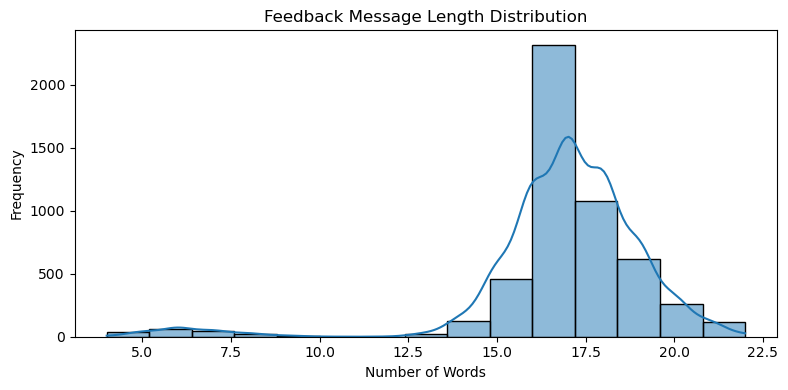

Sentiment by Service:
sentiment           Negative  Neutral  Positive
service_category                               
Billing & Payments       345       94       432
Broadband Service        356       82       433
Customer Support         343      100       415
Mobile App Issues        342       77       434
Mobile Network           364       88       432
Service Activation       349       69       420

Average Feedback Length:
count    5175.000000
mean       16.868986
std         2.490538
min         4.000000
25%        16.000000
50%        17.000000
75%        18.000000
max        22.000000
Name: text_length, dtype: float64


In [39]:
# 3. Sentiment by service category
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_raw,
    x="service_category",
    hue="sentiment"
)
plt.title("Sentiment Across Service Categories")
plt.xlabel("Service Type")
plt.ylabel("Feedback Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("service_sentiment.png")
plt.show()


# 4. Feedback text length
df_raw["text_length"] = df_raw["feedback_text"].str.split().str.len()

plt.figure(figsize=(8, 4))
sns.histplot(df_raw["text_length"], bins=15, kde=True)
plt.title("Feedback Message Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("text_length.png")
plt.show()


# 5. Sentiment and service cross-tabulation
print("Sentiment by Service:")
print(pd.crosstab(
    df_raw["service_category"],
    df_raw["sentiment"]
))

print("\nAverage Feedback Length:")
print(df_raw["text_length"].describe())

# Train models

In [40]:
# 1. Split
x_sent = df['feedback_text']
y_sent = df['sentiment']

x_sent_train, x_sent_test, y_sent_train, y_sent_test = train_test_split(
    x_sent, y_sent, test_size=0.2, random_state=42, stratify=y_sent
)

# 2. Vectorize & Train
tfidf_sent = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
x_sent_train_vec = tfidf_sent.fit_transform(x_sent_train)
x_sent_test_vec = tfidf_sent.transform(x_sent_test)

sentiment_model = LogisticRegression(max_iter=1000, class_weight='balanced')
sentiment_model.fit(x_sent_train_vec, y_sent_train)

# 3. Predict
y_sent_pred = sentiment_model.predict(x_sent_test_vec)
y_sent_proba = sentiment_model.predict_proba(x_sent_test_vec)

# 4. Evaluate
print("=== SENTIMENT MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_sent_test, y_sent_pred):.4f}\n")

print("Classification Report:")
print(classification_report(y_sent_test, y_sent_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_sent_test, y_sent_pred))

=== SENTIMENT MODEL EVALUATION ===
Accuracy: 0.9971

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       420
     Neutral       0.99      1.00      1.00       102
    Positive       1.00      1.00      1.00       513

    accuracy                           1.00      1035
   macro avg       1.00      1.00      1.00      1035
weighted avg       1.00      1.00      1.00      1035

Confusion Matrix:
[[418   1   1]
 [  0 102   0]
 [  1   0 512]]


In [41]:
# 1. Split
x_cat = df['feedback_text']
y_cat = df['service_category']

x_cat_train, x_cat_test, y_cat_train, y_cat_test = train_test_split(
    x_cat, y_cat, test_size=0.2, random_state=42, stratify=y_cat
)

# 2. Vectorize & Train
tfidf_cat = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
x_cat_train_vec = tfidf_cat.fit_transform(x_cat_train)
x_cat_test_vec = tfidf_cat.transform(x_cat_test)

category_model = LogisticRegression(max_iter=1000, class_weight='balanced')
category_model.fit(x_cat_train_vec, y_cat_train)

# 3. Predict
y_cat_pred = category_model.predict(x_cat_test_vec)
y_cat_proba = category_model.predict_proba(x_cat_test_vec)

# 4. Evaluate
print("=== SERVICE CATEGORY MODEL EVALUATION ===")
print(f"Accuracy: {accuracy_score(y_cat_test, y_cat_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_cat_test, y_cat_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_cat_test, y_cat_pred))

=== SERVICE CATEGORY MODEL EVALUATION ===
Accuracy: 0.9990

Classification Report:
                    precision    recall  f1-score   support

Billing & Payments       1.00      1.00      1.00       174
 Broadband Service       1.00      0.99      1.00       174
  Customer Support       1.00      1.00      1.00       172
 Mobile App Issues       1.00      1.00      1.00       170
    Mobile Network       0.99      1.00      1.00       177
Service Activation       1.00      1.00      1.00       168

          accuracy                           1.00      1035
         macro avg       1.00      1.00      1.00      1035
      weighted avg       1.00      1.00      1.00      1035

Confusion Matrix:
[[174   0   0   0   0   0]
 [  0 173   0   0   1   0]
 [  0   0 172   0   0   0]
 [  0   0   0 170   0   0]
 [  0   0   0   0 177   0]
 [  0   0   0   0   0 168]]


In [46]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

x_sent = df['feedback_text']
y_sent = df['sentiment']

sent_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sent_cv = cross_validate(
    sent_pipeline,
    x_sent,
    y_sent,
    cv=skf,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'f1_weighted': 'f1_weighted'
    },
    return_train_score=True,
    n_jobs=-1
)

print("=== SENTIMENT 5-FOLD CV ===")
for metric in ['accuracy', 'f1_macro', 'f1_weighted']:
    val_scores = sent_cv[f'test_{metric}']
    train_scores = sent_cv[f'train_{metric}']
    print(f"{metric:12s} | Val: {val_scores.mean():.4f}  | Train: {train_scores.mean():.4f}")

=== SENTIMENT 5-FOLD CV ===
accuracy     | Val: 0.9940  | Train: 0.9986
f1_macro     | Val: 0.9935  | Train: 0.9982
f1_weighted  | Val: 0.9940  | Train: 0.9986


In [47]:
x_cat = df['feedback_text']
y_cat = df['service_category']

cat_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

cat_cv = cross_validate(
    cat_pipeline,
    x_cat,
    y_cat,
    cv=skf,
    scoring={
        'accuracy': 'accuracy',
        'f1_macro': 'f1_macro',
        'f1_weighted': 'f1_weighted'
    },
    return_train_score=True,
    n_jobs=-1
)

print("\n=== SERVICE CATEGORY 5-FOLD CV ===")
for metric in ['accuracy', 'f1_macro', 'f1_weighted']:
    val_scores = cat_cv[f'test_{metric}']
    train_scores = cat_cv[f'train_{metric}']
    print(f"{metric:12s} | Val: {val_scores.mean():.4f}  | Train: {train_scores.mean():.4f}")


=== SERVICE CATEGORY 5-FOLD CV ===
accuracy     | Val: 0.9994  | Train: 1.0000
f1_macro     | Val: 0.9994  | Train: 1.0000
f1_weighted  | Val: 0.9994  | Train: 1.0000


# save mdoels

In [49]:
joblib.dump(tfidf_sent, r'D:\python_projects\zends_project\local\models\tfidf_sent.pkl')
joblib.dump(sentiment_model, r'D:\python_projects\zends_project\local\models\sentiment_model.pkl')
joblib.dump(tfidf_cat, r'D:\python_projects\zends_project\local\models\tfidf_cat.pkl')
joblib.dump(category_model, r'D:\python_projects\zends_project\local\models\category_model.pkl')

print('saved successfully')

saved successfully
